<a href="https://colab.research.google.com/github/asciosh/lumen-x/blob/main/notebooks/03_global_lightgbm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · Modello globale LightGBM
Un solo modello addestrato su **tutte le serie** (54 negozi x 33 famiglie di prodotto) del dataset Store Sales, confrontato con il naive stagionale. Backtesting su 3 finestre da 28 giorni alla fine del periodo, poi analisi degli errori per famiglia e per finestra.

Target: `log1p(vendite)`, così serie con volumi molto diversi pesano in modo comparabile. Metriche: **WAPE** (errore assoluto totale / vendite totali) e **RMSLE**.

## 1. Dati
Dataset: **Store Sales - Time Series Forecasting** (Kaggle). La chiave API è nei Secrets di Colab come `KAGGLE_API_TOKEN` (mai nel codice). Se i dati sono già in `data/` (stessa sessione del notebook 02) puoi saltare la cella.

In [2]:
import os
from google.colab import userdata

!pip install -q -U kaggle
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!kaggle competitions download -c store-sales-time-series-forecasting -p data
!unzip -oq data/store-sales-time-series-forecasting.zip -d data
!ls data

100% 21.4M/21.4M [00:00<00:00, 163MB/s] 

holidays_events.csv			 stores.csv
oil.csv					 test.csv
sample_submission.csv			 train.csv
store-sales-time-series-forecasting.zip  transactions.csv


## 2. Dataset in formato lungo
Partiamo da una tabella larga (date x serie) per calcolare lag e medie mobili, poi la trasformiamo in una riga per (data, negozio, famiglia). Anti-leakage: lag e medie mobili usano solo dati di almeno 28 giorni prima, cioè l'orizzonte.

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
import lightgbm as lgb
warnings.filterwarnings("ignore")

H = 28
train = pd.read_csv("data/train.csv", parse_dates=["date"])
stores = pd.read_csv("data/stores.csv")
hol = pd.read_csv("data/holidays_events.csv", parse_dates=["date"])

dates = pd.date_range(train["date"].min(), train["date"].max(), freq="D")
wide = train.set_index(["date", "store_nbr", "family"])
Y = wide["sales"].unstack(["store_nbr", "family"]).reindex(dates)
P = wide["onpromotion"].unstack(["store_nbr", "family"]).reindex(dates)
P = P.reindex(columns=Y.columns).fillna(0)
L = np.log1p(Y)
n_d, n_s = L.shape
print(f"{n_d} giorni x {n_s} serie")

1688 giorni x 1782 serie


In [4]:
feats = {}
for lag in (28, 35, 42, 56, 91, 364):
    feats[f"lag_{lag}"] = L.shift(lag)
for w in (7, 28):
    feats[f"roll_mean_{w}"] = L.shift(H).rolling(w, min_periods=1).mean()
feats["promo"] = P
feats["y"] = L

df = pd.DataFrame({
    "date": np.repeat(dates.values, n_s),
    "store_nbr": np.tile(L.columns.get_level_values("store_nbr").values, n_d),
    "family": np.tile(L.columns.get_level_values("family").values, n_d),
    "t": np.repeat(np.arange(n_d), n_s),
    "s": np.tile(np.arange(n_s), n_d),
})
for k, v in feats.items():
    df[k] = v.to_numpy(dtype="float32").ravel()

d = pd.DatetimeIndex(df["date"])
nat = hol[(hol.locale == "National") & (~hol.transferred) & (hol.type != "Work Day")]
df["dow"] = d.dayofweek
df["dom"] = d.day
df["month"] = d.month
df["doy"] = d.dayofyear
df["payday"] = ((d.day == 15) | d.is_month_end).astype(int)
df["holiday"] = d.isin(set(nat.date)).astype(int)

df = df.merge(stores[["store_nbr", "cluster", "type"]], on="store_nbr", how="left")
for c in ("store_nbr", "family", "type"):
    df[c] = df[c].astype("category")

df = df[df["y"].notna()].reset_index(drop=True)   # toglie il 25 dicembre (negozi chiusi)
FEATURES = [c for c in df.columns if c not in ("date", "t", "s", "y")]
print(df.shape, FEATURES)

(3000888, 23) ['store_nbr', 'family', 'lag_28', 'lag_35', 'lag_42', 'lag_56', 'lag_91', 'lag_364', 'roll_mean_7', 'roll_mean_28', 'promo', 'dow', 'dom', 'month', 'doy', 'payday', 'holiday', 'cluster', 'type']


## 3. Metriche, baseline e modello

In [5]:
def wape(a, p):
    return np.abs(a - p).sum() / a.sum() * 100

def rmsle(a, p):
    return np.sqrt(np.mean((np.log1p(p) - np.log1p(a)) ** 2))

Yf = Y.ffill().fillna(0).to_numpy()   # per il naive stagionale

def run_fold(end):
    tr = df[(df["t"] < end) & (df["t"] >= 365)]       # il primo anno non ha lag_364
    te = df[(df["t"] >= end) & (df["t"] < end + H)].copy()

    model = lgb.LGBMRegressor(
        n_estimators=300, learning_rate=0.05, num_leaves=63, min_child_samples=50,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        random_state=42, verbose=-1,
    )
    model.fit(tr[FEATURES], tr["y"])

    te["actual"] = np.expm1(te["y"])
    te["LightGBM"] = np.expm1(model.predict(te[FEATURES])).clip(0)
    k = te["t"].to_numpy() - end
    te["naive"] = Yf[end - 7 + (k % 7), te["s"].to_numpy()]   # ripete l'ultima settimana
    te["fold"] = end
    return te[["date", "store_nbr", "family", "fold", "actual", "naive", "LightGBM"]], model

## 4. Backtesting (3 finestre da 28 giorni)
Ci vuole qualche minuto: il modello viene riaddestrato su tutte le serie a ogni finestra.

In [6]:
ends = [n_d - H * k for k in (3, 2, 1)]
parts, model = [], None
for e in ends:
    part, model = run_fold(e)
    parts.append(part)
    print("finestra pronta:", part["date"].min().date(), "->", part["date"].max().date())
pred = pd.concat(parts, ignore_index=True)

finestra pronta: 2017-05-24 -> 2017-06-20
finestra pronta: 2017-06-21 -> 2017-07-18
finestra pronta: 2017-07-19 -> 2017-08-15


## 5. Risultati

In [7]:
rows = []
for f, g in pred.groupby("fold"):
    for m in ("naive", "LightGBM"):
        rows.append({"finestra": g["date"].min().date(), "modello": m,
                     "WAPE": wape(g["actual"], g[m]), "RMSLE": rmsle(g["actual"], g[m])})
by_fold = pd.DataFrame(rows)

summary = by_fold.groupby("modello")[["WAPE", "RMSLE"]].mean().round(3).sort_values("WAPE")
print(summary.to_markdown())
by_fold.pivot(index="finestra", columns="modello", values="WAPE").round(2)

| modello   |   WAPE |   RMSLE |
|:----------|-------:|--------:|
| LightGBM  |   13.5 |   0.413 |
| naive     |   17.1 |   0.55  |


modello,LightGBM,naive
finestra,,
2017-05-24,14.22,16.75
2017-06-21,12.08,17.32
2017-07-19,14.20,17.24


## 6. Dove sbaglia di più
Errore (WAPE) per famiglia di prodotto: le famiglie piccole e irregolari sono le più difficili.

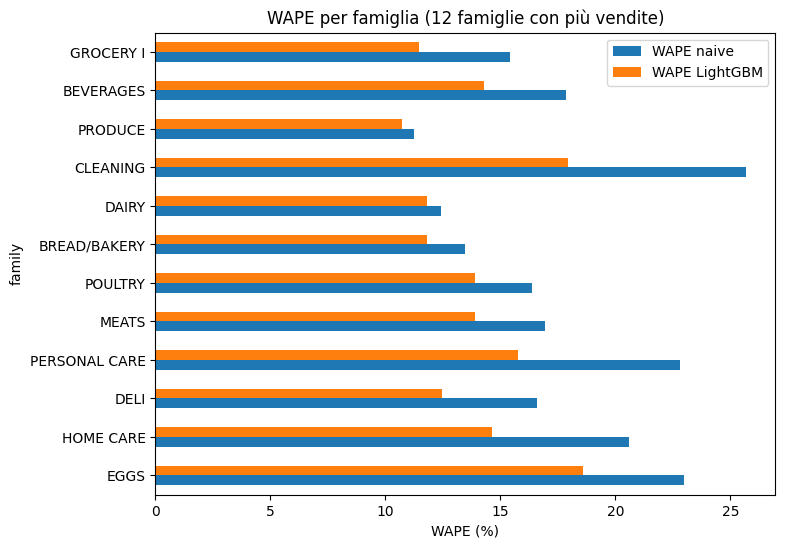

In [8]:
fam = (pred.groupby("family", observed=True)
           .apply(lambda g: pd.Series({
               "vendite": g["actual"].sum(),
               "WAPE naive": wape(g["actual"], g["naive"]),
               "WAPE LightGBM": wape(g["actual"], g["LightGBM"]),
           }))
           .sort_values("vendite", ascending=False))

top = fam.head(12).sort_values("vendite")
top[["WAPE naive", "WAPE LightGBM"]].plot.barh(figsize=(8, 6), title="WAPE per famiglia (12 famiglie con più vendite)")
plt.xlabel("WAPE (%)")
plt.savefig("wape_by_family.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Totale vendite: previsione vs reale (ultima finestra)

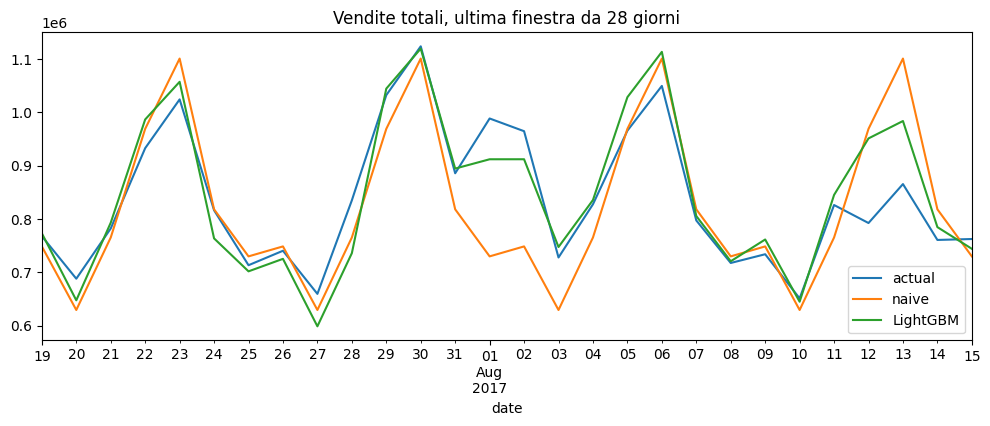

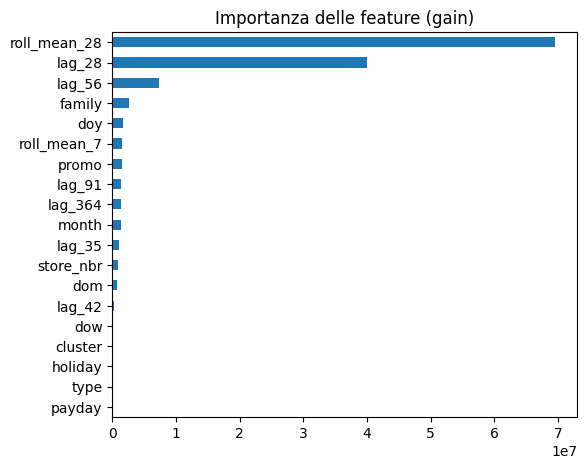

In [9]:
last = pred[pred["fold"] == ends[-1]].groupby("date")[["actual", "naive", "LightGBM"]].sum()
last.plot(figsize=(12, 4), title="Vendite totali, ultima finestra da 28 giorni")
plt.savefig("forecast_global.png", dpi=150, bbox_inches="tight")
plt.show()

imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES).sort_values()
imp.plot.barh(figsize=(6, 5), title="Importanza delle feature (gain)")
plt.savefig("feature_importance_global.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Risultati

Backtesting a finestra espandibile, 3 finestre da 28 giorni, su tutte le serie (54 negozi x 33 famiglie).

| modello  |  WAPE | RMSLE |
|:---------|------:|------:|
| LightGBM |  13.5 | 0.413 |
| naive    |  17.1 | 0.550 |

| finestra   | LightGBM | naive |
|:-----------|---------:|------:|
| 2017-05-24 |    14.22 | 16.75 |
| 2017-06-21 |    12.08 | 17.32 |
| 2017-07-19 |    14.20 | 17.24 |

**Cosa osservo**
- Il modello globale batte il naive in tutte e tre le finestre: WAPE -21% e RMSLE -25% in media.
- *(Famiglie con errore più alto: guarda il grafico WAPE per famiglia e scrivi quali sono e perché)*
- *(Feature più importanti: guarda il grafico di importanza e scrivi le prime tre)*
- Limiti: solo 3 finestre recenti, nessun tuning, nessuna feature esterna (petrolio, transazioni, festività locali).
- Prossimi passi: tuning, feature aggiuntive, intervalli di previsione e servizio API.